In [7]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 3.9 MB/s  0:00:02m 4.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 4.5 MB/s  0:00:04 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]
Note: you may need to restart the kernel to use updated packages.


In [20]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
import sys


In [2]:
df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()
print(df_clean.shape, temp.shape, len(train_buildings))

(17544, 1578) (17544, 19) 1083


In [3]:
b = "Robin_lodging_Dorthy"
site = b.split("_")[0]
s = df_clean[b]

feat = pd.DataFrame({
    "load": s,
    "hour": s.index.hour,
    "weekday": s.index.weekday,
    "lag24": s.shift(24),
    "lag168": s.shift(168),
    "temp": temp[site],
})
feat.loc["2016-01-08":].head(10)

,load,hour,weekday,lag24,lag168,temp
2016-01-08 00:00:00,33.4,0,4,32.6,14.3,3.3
2016-01-08 01:00:00,28.0,1,4,25.4,27.3,3.2
2016-01-08 02:00:00,23.9,2,4,20.8,25.7,2.6
2016-01-08 03:00:00,20.4,3,4,19.2,22.4,2.7
2016-01-08 04:00:00,19.8,4,4,18.4,20.1,1.9
2016-01-08 05:00:00,19.6,5,4,18.1,18.6,2.4
2016-01-08 06:00:00,19.2,6,4,17.7,17.4,1.6
2016-01-08 07:00:00,20.1,7,4,19.5,19.5,4.2
2016-01-08 08:00:00,24.6,8,4,22.9,22.1,4.4
2016-01-08 09:00:00,32.3,9,4,30.7,26.1,5.8


In [4]:
features = ["hour", "weekday", "lag24", "lag168", "temp"]

train = feat.loc["2016"].dropna(subset=["load"])
test = feat.loc["2017"].dropna(subset=["load"])

model = HistGradientBoostingRegressor(random_state=0)
model.fit(train[features], train["load"])

pred = model.predict(test[features])
mae_model = (test["load"] - pred).abs().mean()
print("model MAE:", round(mae_model, 2), " | baselines: last week 3.42, yesterday 3.00")

model MAE: 2.56  | baselines: last week 3.42, yesterday 3.00


In [5]:
features_no_temp = ["hour", "weekday", "lag24", "lag168"]

model2 = HistGradientBoostingRegressor(random_state=0)
model2.fit(train[features_no_temp], train["load"])
pred2 = model2.predict(test[features_no_temp])
mae_no_temp = (test["load"] - pred2).abs().mean()
print("with temp:", round(mae_model, 2), " | without temp:", round(mae_no_temp, 2), " | yesterday:", 3.00)

with temp: 2.56  | without temp: 2.57  | yesterday: 3.0


In [6]:


# 4. Train and score two models: with and without temperature
def train_and_score(features):
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(train[features], train["load"])
    pred = model.predict(test[features])
    return (test["load"] - pred).abs().mean()

mae_with = train_and_score(["hour", "weekday", "lag24", "lag168", "temp"])
mae_without = train_and_score(["hour", "weekday", "lag24", "lag168"])

# 5. Baselines on the same test hours
mae_yesterday = (test["load"] - test["lag24"]).abs().mean()
mae_lastweek = (test["load"] - test["lag168"]).abs().mean()

print("model with temp:   ", round(mae_with, 2))
print("model without temp:", round(mae_without, 2))
print("baseline yesterday:", round(mae_yesterday, 2))
print("baseline last week:", round(mae_lastweek, 2))

model with temp:    2.56
model without temp: 2.57
baseline yesterday: 3.0
baseline last week: 3.42


In [7]:
# as it can be seen the temp feature do not change the result so much, it might be because of the type or location of the building after experimenting on all the building we can conclude the role of temp on the model



In [8]:
# Global model
import numpy as np

rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)

def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site]})

data = pd.concat([make_features(b) for b in sample])
features = ["hour", "weekday", "lag24", "lag168", "temp"]

train = data[data.index.year == 2016].dropna(subset=["load"])
test = data[data.index.year == 2017].dropna(subset=["load"]).copy()

model = HistGradientBoostingRegressor(random_state=0)
model.fit(train[features], train["load"])
test["pred"] = model.predict(test[features])

by_b = test.groupby("building")
mae_model = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
mae_yest = by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean())
mae_week = by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean())
best_base = np.minimum(mae_yest, mae_week)

print(len(train), "training rows")
print("model beats the stronger baseline for", (mae_model < best_base).mean().round(2), "of buildings")
print("median improvement:", ((best_base - mae_model) / best_base).median().round(3))

851136 training rows
model beats the stronger baseline for 0.58 of buildings
median improvement: 0.025


In [9]:
# for 4 out of 10 buildings, copying yesterday or last week is still better.

In [10]:
scale = train.groupby("building")["load"].mean()

for df in (train, test):
    df["scale"] = df["building"].map(scale)
    for col in ["load", "lag24", "lag168"]:
        df[col + "_n"] = df[col] / df["scale"]

features_n = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]

model_n = HistGradientBoostingRegressor(random_state=0)
model_n.fit(train[features_n], train["load_n"])
test["pred_n"] = model_n.predict(test[features_n]) * test["scale"]

mae_model_n = test.groupby("building").apply(lambda g: (g["load"] - g["pred_n"]).abs().mean())
print("normalised model beats the stronger baseline for", (mae_model_n < best_base).mean().round(2), "of buildings")
print("median improvement:", ((best_base - mae_model_n) / best_base).median().round(3))

normalised model beats the stronger baseline for 0.75 of buildings
median improvement: 0.099


In [11]:
# Per-building normalisation, with the scale computed on training data only, raised the share of buildings beating the stronger naive baseline from 58% to 75%.


In [12]:
improve = (best_base - mae_model_n) / best_base
result = pd.DataFrame({"improve": improve,
                       "type": improve.index.str.split("_").str[1],
                       "site": improve.index.str.split("_").str[0]})
print(result.groupby("type")["improve"].agg(["median", "count"]).sort_values("median"))
print(result.sort_values("improve").head(10))

              median  count
type                       
services   -0.159360      1
industrial -0.027197      2
lodging    -0.022637     11
parking    -0.019219      2
health      0.028869      1
assembly    0.049470     10
public      0.070946     19
science     0.097188      2
office      0.146388     22
education   0.164558     30
                        improve        type      site
building                                             
Rat_assembly_Pam      -6.499608    assembly       Rat
Hog_office_Gustavo    -1.068769      office       Hog
Moose_education_Maria -0.279781   education     Moose
Fox_parking_Felipa    -0.205985     parking       Fox
Cockatoo_lodging_Kyle -0.185593     lodging  Cockatoo
Bull_services_Nadine  -0.159360    services      Bull
Hog_industrial_Jay    -0.131519  industrial       Hog
Rat_public_Caroline   -0.113877      public       Rat
Rat_assembly_Aisha    -0.111525    assembly       Rat
Rat_assembly_Jamie    -0.095443    assembly       Rat


<Axes: title={'center': 'Rat_assembly_Pam'}>

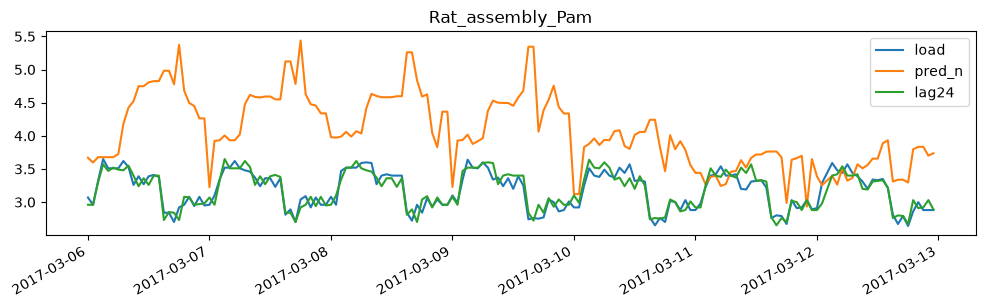

In [13]:
worst = result.sort_values("improve").index[0]
w = test[test["building"] == worst].loc["2017-03-06":"2017-03-12"]
w[["load", "pred_n", "lag24"]].plot(figsize=(12, 3), title=worst)

<Axes: title={'center': 'Rat_assembly_Pam: monthly mean'}, xlabel='timestamp'>

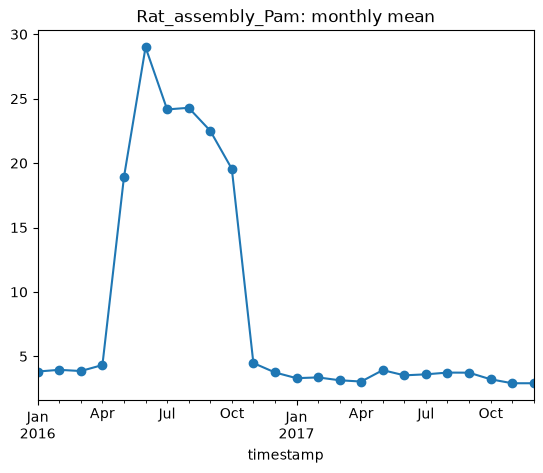

In [14]:
df_clean["Rat_assembly_Pam"].resample("MS").mean().plot(marker="o", title="Rat_assembly_Pam: monthly mean")

In [15]:
# Rat_assembly_Pam used about 4 kWh most of the time, but from May to October 2016 it jumped to about 19–29 kWh, then dropped back to about 3–4 for good. So its 2016 average is pulled far up by those 6 months, and every 2017 forecast gets scaled with a number that no longer describes the building.


In [16]:
def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    recent = recent.where(recent > 0.01)
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site], "scale": recent})

data = pd.concat([make_features(b) for b in sample])
for col in ["load", "lag24", "lag168"]:
    data[col + "_n"] = data[col] / data["scale"]

train = data[data.index.year == 2016].dropna(subset=["load_n"])
test = data[data.index.year == 2017].dropna(subset=["load", "scale"]).copy()

features_n = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
model_r = HistGradientBoostingRegressor(random_state=0)
model_r.fit(train[features_n], train["load_n"])
test["pred"] = model_r.predict(test[features_n]) * test["scale"]

by_b = test.groupby("building")
mae_model = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
best_base = np.minimum(by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean()),
                       by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean()))
improve = (best_base - mae_model) / best_base

print("recent-scale model beats the stronger baseline for", (improve > 0).mean().round(2), "of buildings")
print("median improvement:", improve.median().round(3))
print("Rat_assembly_Pam:", improve["Rat_assembly_Pam"].round(2))

recent-scale model beats the stronger baseline for 0.73 of buildings
median improvement: 0.103
Rat_assembly_Pam: -0.3


In [17]:
# scale	beats stronger baseline	median improvement	Rat_assembly_Pam
# fixed 2016 mean	75%	9.9%	−650%
# recent 7-day mean	73%	10.3%	−30%

In [18]:
def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site],
                         "recent": recent.where(recent > 0.01)})

def run(sample_seed, scale_kind):
    rng = np.random.default_rng(sample_seed)
    sample = rng.choice(train_buildings, size=100, replace=False)
    data = pd.concat([make_features(b) for b in sample])

    if scale_kind == "fixed2016":
        m = data[data.index.year == 2016].groupby("building")["load"].mean()
        data["scale"] = data["building"].map(m)
    else:
        data["scale"] = data["recent"]
    for col in ["load", "lag24", "lag168"]:
        data[col + "_n"] = data[col] / data["scale"]

    train = data[data.index.year == 2016].dropna(subset=["load_n"])
    test = data[data.index.year == 2017].dropna(subset=["load", "recent", "scale"]).copy()

    feats = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(train[feats], train["load_n"])
    test["pred"] = model.predict(test[feats]) * test["scale"]

    by_b = test.groupby("building")
    mae = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
    base = np.minimum(by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean()),
                      by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean()))
    improve = (base - mae) / base
    return {"share": (improve > 0).mean(), "median": improve.median()}

rows = []
for seed in [0, 1, 2]:
    for kind in ["fixed2016", "recent"]:
        print("running seed", seed, kind)
        rows.append({"seed": seed, "scale": kind, **run(seed, kind)})

results = pd.DataFrame(rows)
results.pivot(index="seed", columns="scale", values=["share", "median"]).round(3)

running seed 0 fixed2016
running seed 0 recent
running seed 1 fixed2016
running seed 1 recent
running seed 2 fixed2016
running seed 2 recent


share           median       
scale fixed2016 recent fixed2016 recent
seed                                   
0          0.75   0.73     0.099  0.103
1          0.75   0.72     0.115  0.098
2          0.75   0.79     0.082  0.100

In [22]:

def make_features(b, df_clean, temp):
    """Feature table for one building: one row per hour."""
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    feat = pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site],
                         "scale": recent.where(recent > 0.01)})
    for col in ["load", "lag24", "lag168"]:
        feat[col + "_n"] = feat[col] / feat["scale"]
    return feat

In [26]:
sys.path.append("..")
from src.features import make_features

feat = make_features("Robin_lodging_Dorthy", df_clean, temp)
feat.loc["2016-01-15"].head(3)

,building,load,hour,weekday,lag24,lag168,temp,scale,load_n,lag24_n,lag168_n
2016-01-15 00:00:00,Robin_lodging_Dorthy,35.8,0,4,36.5,33.4,2.1,34.245238,1.045401,1.065842,0.975318
2016-01-15 01:00:00,Robin_lodging_Dorthy,28.5,1,4,28.4,28.0,2.0,34.263095,0.831799,0.828880,0.817206
2016-01-15 02:00:00,Robin_lodging_Dorthy,24.9,2,4,23.5,23.9,1.6,34.279167,0.726389,0.685548,0.697216


In [27]:
import src
print(src.__file__)

/Users/sevilkhojasteh/Documents/to-learn/projects/building-energy-trust/notebooks/../src/__init__.py


In [28]:
# global model Vs. one model per building
# although one model per building has some advantages: privacy, low bad data, capturing one building's bad behavior, the global model has a cold start
# so it can predict an unseen building without any further effort
# that’s exactly why your project has a federated part. Federated learning tries to get a global model’s benefits (shared patterns, cold start) without collecting the data in one place




In [29]:
# The global gradient-boosting model beats the stronger naive baseline for 76.3% ± 0.3% of buildings, with a median improvement of 10.7% ± 0.1% (5 seeds).